## Importing libraries and unzipping the data

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shutil as sh 
!mv ~/Downloads/ml-latest-small.zip .
sh.unpack_archive(filename="ml-latest-small.zip", extract_dir="data")

## Remove the unwanted files

In [6]:
!rm ml-latest-small.zip
!rm data/ml-latest-small/README.txt
!rm data/ml-latest-small/links.csv data/ml-latest-small/tags.csv
!path=$(pwd) && mv data/ml-latest-small/ratings.csv $path 
!path=$(pwd) && mv data/ml-latest-small/movies.csv $path

## Loading the data frames

In [19]:
movies_df = pd.read_csv("movies.csv")
ratings_df = pd.read_csv("ratings.csv")

## Showing sample of movies data frame

In [20]:
movies_df.head(20)

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action|Crime|Thriller
6,7,Sabrina (1995),Comedy|Romance
7,8,Tom and Huck (1995),Adventure|Children
8,9,Sudden Death (1995),Action
9,10,GoldenEye (1995),Action|Adventure|Thriller


## showing sample of ratings data frame

In [21]:
ratings_df.head(20)

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931
5,1,70,3.0,964982400
6,1,101,5.0,964980868
7,1,110,4.0,964982176
8,1,151,5.0,964984041
9,1,157,5.0,964984100


## exploring movies data frame 

In [22]:
movies_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 228.5 KB


## exploring ratings data frame

In [23]:
ratings_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


## printing the report 

In [27]:
#defining the variables 
unique_users = ratings_df["userId"].nunique()
unique_movies = movies_df["movieId"].nunique()
unique_rated_movies = ratings_df["movieId"].nunique()
ratings = ratings_df["rating"].count()
all_ratings = unique_users * unique_movies
sparisty = (1 - (ratings / all_ratings)) * 100

#printing the results 
print("Number of unique users in the dataset --> ", unique_users)
print("Number of unique movies (rated and unrated) --> ", unique_movies)
print("Number of unique movies that have been rated --> ", unique_rated_movies)
print("Number of ratings in the dataset -->", ratings)
print("number of pairs of users and movies that have no ratings --> ", round(sparisty, 2), "%")

Number of unique users in the dataset -->  610
Number of unique movies (rated and unrated) -->  9742
Number of unique movies that have been rated -->  9724
Number of ratings in the dataset --> 100836
number of pairs of users and movies that have no ratings -->  98.3 %


## Creating the user movie data frame 

In [32]:
user_movie_df = pd.pivot_table(
    data = ratings_df,
    index = "userId",
    columns = "movieId",
    values = "rating",
    fill_value = pd.NA)

## Showing a sample of user_moview data frame

In [33]:
user_movie_df.head(20)

movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,4.0,5.0,3.0,5.0,4.0,4.0,3.0,NaN,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,4.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## exploring the data frame 

In [37]:
user_movie_df.info()
print("Dimensions of the data frame --> ", user_movie_df.shape)

<class 'pandas.DataFrame'>
Index: 610 entries, 1 to 610
Columns: 9724 entries, 1 to 193609
dtypes: float64(9724)
memory usage: 45.3 MB
Dimensions of the data frame -->  (610, 9724)


## plotting the ditribution of the ratings 

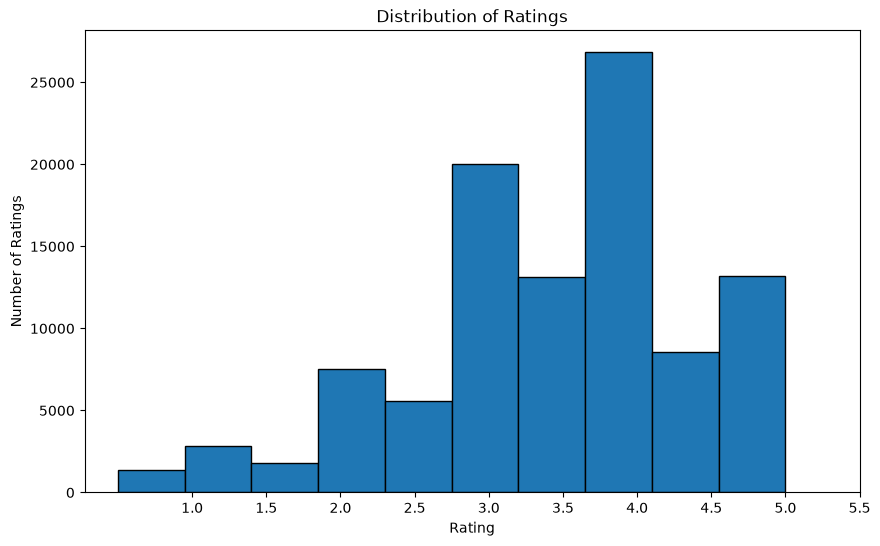

In [64]:
plt.figure(figsize=(10, 6))
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.hist(ratings_df["rating"], bins=10, edgecolor="black")
plt.xticks(np.arange(1, 6, 0.5))
plt.show()

## plot the number of the ratings of each user

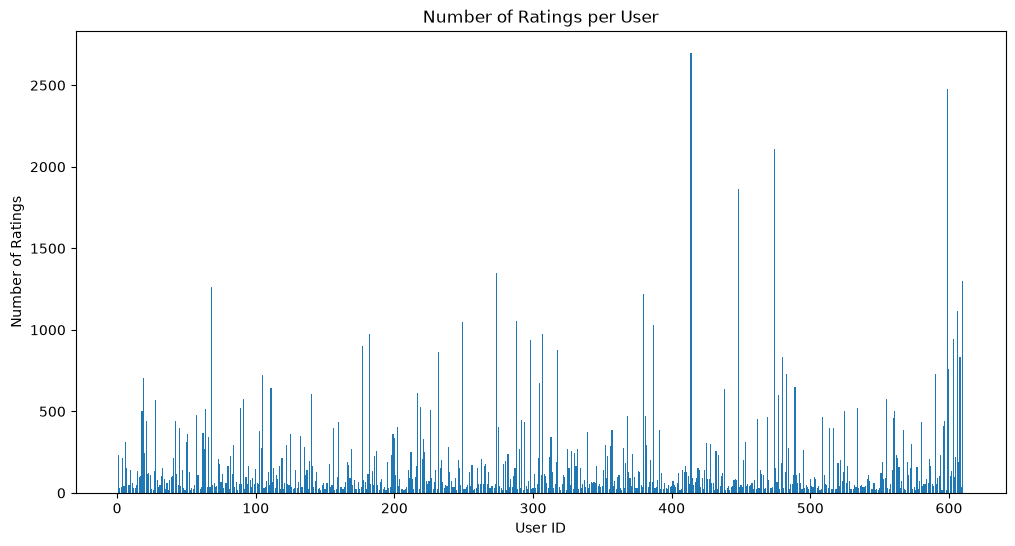

In [69]:
plt.figure(figsize=(12, 6))
ratings_per_user = ratings_df.groupby("userId")["rating"].count()
plt.bar(ratings_per_user.index, ratings_per_user.values)
plt.title("Number of Ratings per User")
plt.xlabel("User ID")
plt.ylabel("Number of Ratings")
plt.show()

## implementing get_co_rated function

In [71]:
def get_co_rated(matrix , a , b , axis):
    if axis == "index":
        a_rated = matrix.loc[a]
        b_rated = matrix.loc[b]
        common_indeces = a_rated.notna() & b_rated.notna()
        a_rated = a_rated[common_indeces]
        b_rated = b_rated[common_indeces]
        return a_rated, b_rated
    elif axis == "columns":
        a_rated = matrix.loc[:, a]
        b_rated = matrix.loc[:, b]
        common_indeces = a_rated.notna() & b_rated.notna()
        a_rated = a_rated[common_indeces]
        b_rated = b_rated[common_indeces]
        return a_rated, b_rated

## Testing the previous function 

In [75]:
a_rated, b_rated = get_co_rated(user_movie_df, 1, 2, axis="index")
print(a_rated)
print(b_rated)
print("-"*20)
a_rated, b_rated = get_co_rated(user_movie_df, 1, 2, axis="columns")
print(a_rated)
print(b_rated)

movieId
333     5.0
3578    5.0
Name: 1, dtype: float64
movieId
333     4.0
3578    4.0
Name: 2, dtype: float64
--------------------
userId
18     3.5
19     4.0
21     3.5
27     3.0
68     2.5
      ... 
599    3.0
600    2.5
604    3.0
605    4.0
608    2.5
Name: 1, Length: 68, dtype: float64
userId
18     3.0
19     3.0
21     3.5
27     4.0
68     2.5
      ... 
599    2.5
600    4.0
604    5.0
605    3.5
608    2.0
Name: 2, Length: 68, dtype: float64
